In [1]:
# Build a CNN for Image Classification
# o Build a simple CNN (e.g., 2 conv layers + FC) for CIFAR-10.
# o Compare with MLP performance.
# o Use basic data augmentation

In [7]:
# Import libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import time

In [8]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/cifar/cifar10/train",
    image_size=(32, 32),
    batch_size=64,
    validation_split=0.1,
    subset="training",
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/cifar/cifar10/train",
    image_size=(32, 32),
    batch_size=64,
    validation_split=0.1,
    subset="validation",
    seed=42
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/cifar/cifar10/test",
    image_size=(32, 32),
    batch_size=64
)

print("Classes:", train_ds.class_names)

Found 50000 files belonging to 10 classes.
Using 45000 files for training.
Found 50000 files belonging to 10 classes.
Using 5000 files for validation.
Found 10000 files belonging to 10 classes.
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [9]:
# Prepare MLP data
mlp_train = train_ds.map(lambda x, y: (tf.reshape(x / 255.0, [-1, 3072]), y))
mlp_val = val_ds.map(lambda x, y: (tf.reshape(x / 255.0, [-1, 3072]), y))
mlp_test = test_ds.map(lambda x, y: (tf.reshape(x / 255.0, [-1, 3072]), y))

# Prepare CNN data
cnn_train = train_ds.map(lambda x, y: (x / 255.0, y))
cnn_val = val_ds.map(lambda x, y: (x / 255.0, y))
cnn_test = test_ds.map(lambda x, y: (x / 255.0, y))

In [10]:
# Build and train MLP model
mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3072,)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

mlp.compile(
    optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

start = time.time()

h1 = mlp.fit(
    mlp_train,
    epochs=5,
    validation_data=mlp_val
)

mlp_time = time.time() - start

mlp_loss, mlp_acc = mlp.evaluate(mlp_test)

print("MLP Accuracy:", mlp_acc * 100, "%")
print("MLP Training Time:", round(mlp_time, 2), "seconds")

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 50s 70ms/step - accuracy: 0.3137 - loss: 1.9165 - val_accuracy: 0.3426 - val_loss: 1.8325
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 44s 62ms/step - accuracy: 0.3784 - loss: 1.7468 - val_accuracy: 0.3796 - val_loss: 1.7354
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 44s 62ms/step - accuracy: 0.4030 - loss: 1.6832 - val_accuracy: 0.3728 - val_loss: 1.7270
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 42s 60ms/step - accuracy: 0.4171 - loss: 1.6430 - val_accuracy: 0.3784 - val_loss: 1.7196
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 41s 58ms/step - accuracy: 0.4274 - loss: 1.6134 - val_accuracy: 0.3722 - val_loss: 1.7338
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 53ms/step - accuracy: 0.3917 - loss: 1.6925
MLP Accuracy: 39.169999957084656 %
MLP Training Time: 221.47 seconds


In [11]:
# Build and train CNN with data augmentation
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

start = time.time()

h2 = cnn.fit(
    cnn_train,
    epochs=5,
    validation_data=cnn_val
)

cnn_time = time.time() - start

cnn_loss, cnn_acc = cnn.evaluate(cnn_test)

print("CNN Accuracy:", cnn_acc * 100, "%")
print("CNN Training Time:", round(cnn_time, 2), "seconds")

Epoch 1/5
  1/704 ━━━━━━━━━━━━━━━━━━━━ 25:47 2s/step - accuracy: 0.2031 - loss: 2.2916

W0000 00:00:1794470133.150198   13028 cpu_allocator_impl.cc:82] Allocation of 19663488 exceeds 10% of free system memory.
W0000 00:00:1794470133.153861   13026 cpu_allocator_impl.cc:82] Allocation of 19663488 exceeds 10% of free system memory.
W0000 00:00:1794470133.284169   13025 cpu_allocator_impl.cc:82] Allocation of 14191200 exceeds 10% of free system memory.


  2/704 ━━━━━━━━━━━━━━━━━━━━ 2:32 217ms/step - accuracy: 0.1562 - loss: 2.3044

W0000 00:00:1794470133.421262   13025 cpu_allocator_impl.cc:82] Allocation of 19663488 exceeds 10% of free system memory.
W0000 00:00:1794470133.425409   13028 cpu_allocator_impl.cc:82] Allocation of 19663488 exceeds 10% of free system memory.


704/704 ━━━━━━━━━━━━━━━━━━━━ 53s 72ms/step - accuracy: 0.4146 - loss: 1.6157 - val_accuracy: 0.5078 - val_loss: 1.3870
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 48s 68ms/step - accuracy: 0.5252 - loss: 1.3301 - val_accuracy: 0.5490 - val_loss: 1.2428
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 81s 67ms/step - accuracy: 0.5693 - loss: 1.2180 - val_accuracy: 0.5652 - val_loss: 1.2095
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 48s 68ms/step - accuracy: 0.5949 - loss: 1.1536 - val_accuracy: 0.6158 - val_loss: 1.0934
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 49s 70ms/step - accuracy: 0.6157 - loss: 1.0944 - val_accuracy: 0.6164 - val_loss: 1.0758
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 55ms/step - accuracy: 0.6426 - loss: 1.0306
CNN Accuracy: 64.25999999046326 %
CNN Training Time: 279.13 seconds


MLP Accuracy: 39.17 %
CNN Accuracy: 64.26 %


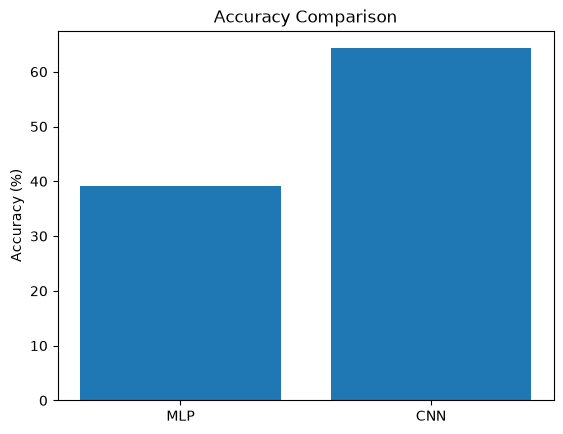

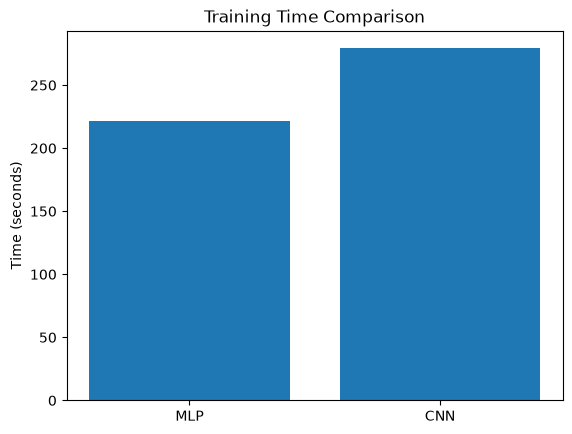

In [12]:
# Compare MLP and CNN performance
print("MLP Accuracy:", round(mlp_acc*100, 2), "%")
print("CNN Accuracy:", round(cnn_acc*100, 2), "%")

plt.bar(['MLP', 'CNN'], [mlp_acc*100, cnn_acc*100])
plt.title("Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.show()

plt.bar(['MLP', 'CNN'], [mlp_time, cnn_time])
plt.title("Training Time Comparison")
plt.ylabel("Time (seconds)")
plt.show()

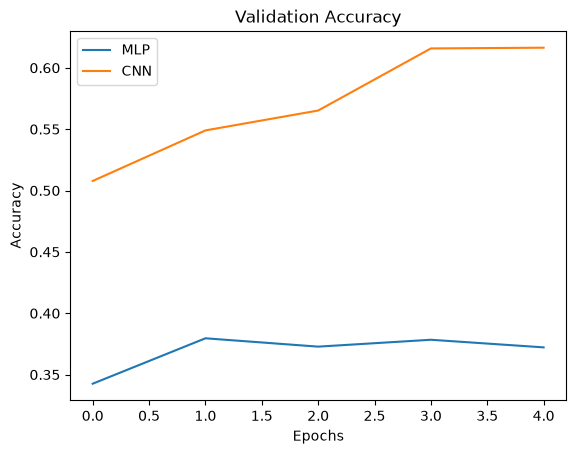

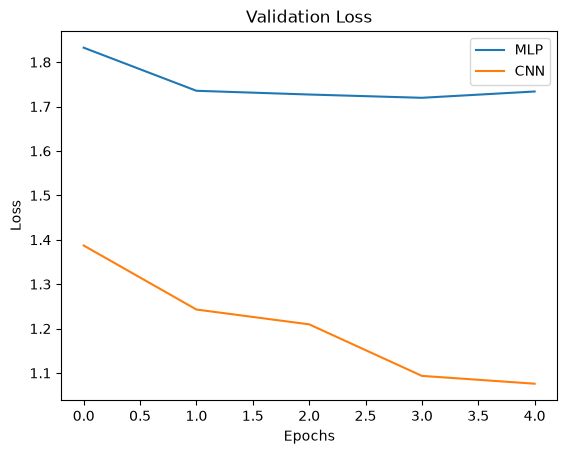

In [13]:
# Plot accuracy and loss curves
plt.plot(h1.history['val_accuracy'], label='MLP')
plt.plot(h2.history['val_accuracy'], label='CNN')
plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(h1.history['val_loss'], label='MLP')
plt.plot(h2.history['val_loss'], label='CNN')
plt.title("Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()